# Análise Exploratória — Produtividade da Soja no Rio Grande do Sul (PAM/IBGE, tabela 1612)

**Projeto:** Predição da Produtividade da Safra de Soja no Rio Grande do Sul com Aprendizado de Máquina e Dados Agrometeorológicos  
**Disciplina:** Inteligência Artificial — N1 (2026)  
**Faculdade de Computação e Informática (FCI) — Universidade Presbiteriana Mackenzie**

**Integrantes:**
- Gabriel Bello — RA 10416808 — 10416808@mackenzista.com.br
- Pedro Giovannini Andrade — RA 10425498 — 10425498@mackenzista.com.br

**Professor:** Prof. Dr. Leandro Zerbinatti

---

**Síntese do conteúdo:** Este notebook captura a tabela 1612 da PAM/IBGE via API SIDRA para os municípios do Rio Grande do Sul e a cultura de Soja (em grão), realiza a preparação dos dados (padronização, tratamento de símbolos SIDRA, tipagem), executa a análise exploratória (cobertura, estatísticas descritivas, distribuições, evolução temporal, correlações e valores extremos) e prepara a base para a etapa de modelagem, integrando também o Oceanic Niño Index (ONI) da NOAA para o sinal ENOS.

**Histórico de alterações:**
| Data | Autor | Descrição |
|---|---|---|
| 2026-09-14 | Pedro Giovannini Andrade | Versão inicial do notebook — captura SIDRA, preparação, EDA e integração ONI. |
| 2026-09-14 | Gabriel Bello | Revisão dos gráficos e ajustes de tratamento de valores ausentes. |


## 1. Importação de bibliotecas e configurações

In [1]:
import os
import io
import json
import time
import warnings
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 100
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 160)

DATA_DIR = os.path.abspath('../dados')
FIG_DIR = os.path.abspath('../figuras')
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)
print('DATA_DIR:', DATA_DIR)
print('FIG_DIR :', FIG_DIR)

/Users/gustavoaugustogarcia/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


Matplotlib is building the font cache; this may take a moment.


DATA_DIR: /Users/gustavoaugustogarcia/Downloads/pedro fedido 2026/dados
FIG_DIR : /Users/gustavoaugustogarcia/Downloads/pedro fedido 2026/figuras


## 2. Captura da base SIDRA/IBGE — tabela 1612 (Produção Agrícola Municipal)

**Fonte:** IBGE/SIDRA — [Tabela 1612](https://sidra.ibge.gov.br/tabela/1612)  
**Filtro:** Nível municipal (`n6`), dentro do estado RS (`n3 43`), cultura `Soja (em grão)` (código 2713), período `2000-2023`.  
**Variáveis coletadas:**

| Código | Variável | Unidade |
|---|---|---|
| 109 | Área plantada | hectares |
| 216 | Área colhida | hectares |
| 214 | Quantidade produzida | toneladas |
| 112 | Rendimento médio da produção | kg/ha (variável-alvo) |
| 215 | Valor da produção | mil reais |

O bloco abaixo baixa os dados pela API SIDRA em requisições ano-a-ano (o endpoint retorna erro 400 quando a lista de anos e variáveis é grande). Caso o arquivo bruto já exista, a etapa é pulada.

In [2]:
raw_csv = os.path.join(DATA_DIR, 'sidra_1612_soja_rs_bruto.csv')

if not os.path.exists(raw_csv):
    variaveis = ['109', '216', '214', '112', '215']
    anos = list(range(2000, 2024))
    all_rows = []
    for ano in anos:
        url = ('https://apisidra.ibge.gov.br/values/t/1612/n6/in%20n3%2043'
               f'/v/{",".join(variaveis)}/p/{ano}/c81/2713?formato=json')
        r = requests.get(url, timeout=120)
        data = r.json()
        all_rows.extend(data[1:])
        print(f'{ano}: {len(data)-1} registros | acumulado {len(all_rows)}')
        time.sleep(0.4)
    pd.DataFrame(all_rows).to_csv(raw_csv, index=False)
    print('Salvo em', raw_csv)
else:
    print('Arquivo bruto já existe:', raw_csv)

Arquivo bruto já existe: /Users/gustavoaugustogarcia/Downloads/pedro fedido 2026/dados/sidra_1612_soja_rs_bruto.csv


## 3. Preparação dos dados

1. Renomear colunas do retorno SIDRA para nomes legíveis;
2. Mapear códigos de variável para nomes curtos;
3. Tratar símbolos especiais do SIDRA (`-`, `..`, `...`, `x`) como valores ausentes;
4. Converter tipos numéricos;
5. Pivotar a base para que cada linha represente um par *município-ano*.


In [3]:
df_raw = pd.read_csv(raw_csv, dtype=str)
print('Shape bruto:', df_raw.shape)

renome = {
    'D1C': 'codigo_municipio',
    'D1N': 'municipio',
    'D2C': 'variavel_cod',
    'D2N': 'variavel_nome',
    'D3C': 'ano',
    'V': 'valor',
    'MN': 'unidade',
}
df = df_raw.rename(columns=renome)[list(renome.values())]

mapa_var = {
    '109': 'area_plantada_ha',
    '216': 'area_colhida_ha',
    '214': 'producao_t',
    '112': 'rendimento_kg_ha',
    '215': 'valor_producao_mil_reais',
}
df['variavel'] = df['variavel_cod'].map(mapa_var)
df['valor'] = df['valor'].replace({'-': np.nan, '..': np.nan, '...': np.nan, 'x': np.nan, 'X': np.nan})
df['valor'] = pd.to_numeric(df['valor'], errors='coerce')
df['ano'] = df['ano'].astype(int)

df.head()

Shape bruto: (59640, 13)


,codigo_municipio,municipio,variavel_cod,variavel_nome,ano,valor,unidade,variavel
0,4300034,Aceguá - RS,109,Área plantada,2000,NaN,Hectares,area_plantada_ha
1,4300034,Aceguá - RS,216,Área colhida,2000,NaN,Hectares,area_colhida_ha
2,4300034,Aceguá - RS,214,Quantidade produzida,2000,NaN,Toneladas,producao_t
3,4300034,Aceguá - RS,112,Rendimento médio da produção,2000,NaN,Quilogramas por Hectare,rendimento_kg_ha
4,4300034,Aceguá - RS,215,Valor da produção,2000,NaN,Mil Reais,valor_producao_mil_reais


In [4]:
base = (
    df.pivot_table(index=['codigo_municipio', 'municipio', 'ano'],
                   columns='variavel', values='valor', aggfunc='first')
      .reset_index()
)
base.columns.name = None
base['municipio_nome'] = base['municipio'].str.replace(' - RS', '', regex=False)
col_order = ['codigo_municipio', 'municipio_nome', 'ano',
             'area_plantada_ha', 'area_colhida_ha', 'producao_t',
             'rendimento_kg_ha', 'valor_producao_mil_reais']
base = base[col_order]
print('Base preparada:', base.shape)
base.head()

Base preparada: (9692, 8)


,codigo_municipio,municipio_nome,ano,area_plantada_ha,area_colhida_ha,producao_t,rendimento_kg_ha,valor_producao_mil_reais
0,4300034,Aceguá,2001,100.0,100.0,126.0,1260.0,47.0
1,4300034,Aceguá,2002,100.0,100.0,126.0,1260.0,55.0
2,4300034,Aceguá,2003,750.0,750.0,945.0,1260.0,624.0
3,4300034,Aceguá,2004,750.0,750.0,945.0,1260.0,650.0
4,4300034,Aceguá,2005,2000.0,2000.0,480.0,240.0,204.0


In [5]:
base.to_csv(os.path.join(DATA_DIR, 'sidra_1612_soja_rs_preparado.csv'), index=False)
print('Salvo:', os.path.join(DATA_DIR, 'sidra_1612_soja_rs_preparado.csv'))

Salvo: /Users/gustavoaugustogarcia/Downloads/pedro fedido 2026/dados/sidra_1612_soja_rs_preparado.csv


## 4. Análise Exploratória

### 4.1 Dimensão, período coberto e cobertura por ano

In [6]:
print(f"Total de linhas (municipio-ano): {len(base):,}")
print(f"Municípios distintos          : {base['codigo_municipio'].nunique():,}")
print(f"Anos cobertos                 : {base['ano'].min()} – {base['ano'].max()}")
print(f"Linhas com rendimento não nulo: {base['rendimento_kg_ha'].notna().sum():,}")
print(f"Linhas com rendimento ausente : {base['rendimento_kg_ha'].isna().sum():,}")

Total de linhas (municipio-ano): 9,692
Municípios distintos          : 452
Anos cobertos                 : 2000 – 2023
Linhas com rendimento não nulo: 9,675
Linhas com rendimento ausente : 17


In [7]:
cobertura = (base.groupby('ano')['rendimento_kg_ha']
                 .apply(lambda s: s.notna().sum())
                 .rename('municipios_com_dado')
                 .reset_index())
print(cobertura.to_string(index=False))

 ano  municipios_com_dado
2000                  350
2001                  374
2002                  379
2003                  390
2004                  396
2005                  390
2006                  397
2007                  392
2008                  395
2009                  395
2010                  395
2011                  395
2012                  399
2013                  404
2014                  410
2015                  413
2016                  415
2017                  424
2018                  423
2019                  424
2020                  426
2021                  425
2022                  429
2023                  435


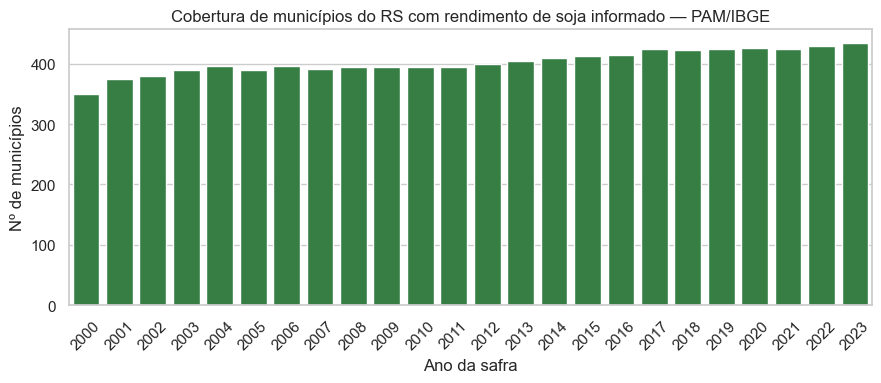

In [8]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(data=cobertura, x='ano', y='municipios_com_dado', color='#2b8a3e', ax=ax)
ax.set_title('Cobertura de municípios do RS com rendimento de soja informado — PAM/IBGE')
ax.set_xlabel('Ano da safra')
ax.set_ylabel('Nº de municípios')
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '01_cobertura_por_ano.png'), dpi=120)
plt.show()

### 4.2 Estatísticas descritivas e valores ausentes

In [9]:
descritivas = base[['area_plantada_ha', 'area_colhida_ha', 'producao_t',
                    'rendimento_kg_ha', 'valor_producao_mil_reais']].describe().T
descritivas

,count,mean,std,min,25%,50%,75%,max
area_plantada_ha,9692.0,11504.024969,17261.592591,1.0,1200.00,5500.0,13600.00,160000.0
area_colhida_ha,9678.0,11423.295826,17190.686681,0.0,1200.00,5500.0,13500.00,160000.0
producao_t,9678.0,27123.924158,44587.200146,0.0,2400.00,11400.0,32183.75,517493.0
rendimento_kg_ha,9675.0,2319.289612,874.958850,105.0,1783.00,2400.0,3000.00,4800.0
valor_producao_mil_reais,9678.0,31431.954846,68006.343444,0.0,1777.25,9294.0,30447.00,1423106.0


In [10]:
ausentes = (base.isna().sum().to_frame('n_ausentes')
                 .assign(pct_ausentes=lambda d: 100 * d['n_ausentes'] / len(base))
                 .sort_values('pct_ausentes', ascending=False))
ausentes

,n_ausentes,pct_ausentes
rendimento_kg_ha,17,0.175402
area_colhida_ha,14,0.144449
producao_t,14,0.144449
valor_producao_mil_reais,14,0.144449
codigo_municipio,0,0.000000
municipio_nome,0,0.000000
ano,0,0.000000
area_plantada_ha,0,0.000000


### 4.3 Distribuição do rendimento (kg/ha)

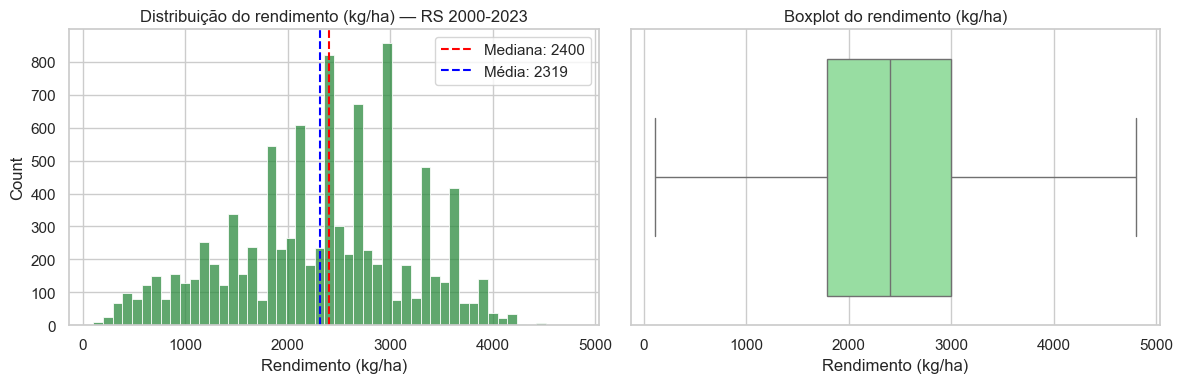

In [11]:
rend = base['rendimento_kg_ha'].dropna()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(rend, bins=50, color='#2b8a3e', ax=axes[0])
axes[0].set_title('Distribuição do rendimento (kg/ha) — RS 2000-2023')
axes[0].set_xlabel('Rendimento (kg/ha)')
axes[0].axvline(rend.median(), color='red', linestyle='--', label=f'Mediana: {rend.median():.0f}')
axes[0].axvline(rend.mean(), color='blue', linestyle='--', label=f'Média: {rend.mean():.0f}')
axes[0].legend()
sns.boxplot(x=rend, color='#8ce99a', ax=axes[1])
axes[1].set_title('Boxplot do rendimento (kg/ha)')
axes[1].set_xlabel('Rendimento (kg/ha)')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '02_distribuicao_rendimento.png'), dpi=120)
plt.show()

### 4.4 Evolução temporal do rendimento estadual

In [12]:
evol = (base.groupby('ano')['rendimento_kg_ha']
             .agg(['mean', 'median', 'std', 'count'])
             .rename(columns={'mean': 'media', 'median': 'mediana',
                              'std': 'desvio', 'count': 'n'})
             .reset_index())
evol

,ano,media,mediana,desvio,n
0,2000,1647.948571,1700.0,467.492712,350
1,2001,2136.288770,2100.0,471.532198,374
2,2002,1701.000000,1800.0,506.072087,379
3,2003,2396.948718,2400.0,533.156741,390
4,2004,1354.224747,1320.0,471.761936,396
5,2005,662.274359,600.0,336.080713,390
6,2006,1873.304786,1900.0,613.087023,397
7,2007,2391.334184,2400.0,541.396218,392
8,2008,1994.875949,2100.0,531.752349,395
9,2009,2065.549367,2100.0,525.905841,395


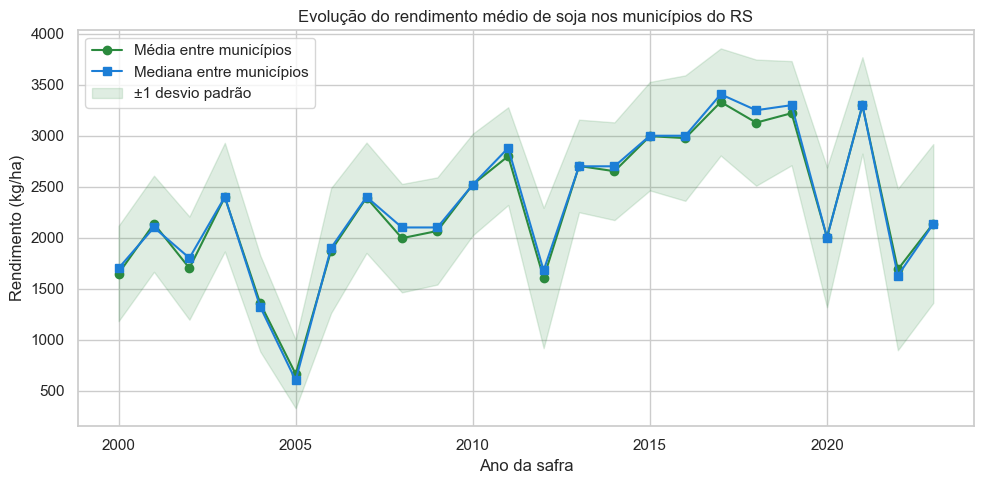

In [13]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(evol['ano'], evol['media'], marker='o', color='#2b8a3e', label='Média entre municípios')
ax.plot(evol['ano'], evol['mediana'], marker='s', color='#1c7ed6', label='Mediana entre municípios')
ax.fill_between(evol['ano'],
                evol['media'] - evol['desvio'],
                evol['media'] + evol['desvio'],
                alpha=0.15, color='#2b8a3e', label='±1 desvio padrão')
ax.set_title('Evolução do rendimento médio de soja nos municípios do RS')
ax.set_xlabel('Ano da safra')
ax.set_ylabel('Rendimento (kg/ha)')
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '03_evolucao_rendimento.png'), dpi=120)
plt.show()

As quebras de safra do RS conhecidas historicamente (2004/2005 — La Niña; 2011/2012 — La Niña forte; 2019/2020; 2021/2022 — La Niña tripla) devem aparecer como vales na série acima.

### 4.5 Coerência entre produção, área colhida e rendimento

Pela definição da PAM, `rendimento_kg_ha ≈ 1000 * producao_t / area_colhida_ha`. Comparar a coluna original com o valor recalculado é um teste de consistência simples.

In [14]:
chk = base.dropna(subset=['producao_t', 'area_colhida_ha', 'rendimento_kg_ha']).copy()
chk = chk[chk['area_colhida_ha'] > 0]
chk['rendimento_recalculado'] = 1000 * chk['producao_t'] / chk['area_colhida_ha']
chk['dif_abs'] = (chk['rendimento_recalculado'] - chk['rendimento_kg_ha']).abs()
chk['dif_pct'] = 100 * chk['dif_abs'] / chk['rendimento_kg_ha']
print('Diferença absoluta (kg/ha) — descritivas:')
print(chk['dif_abs'].describe())
print('\nDiferença percentual — descritivas:')
print(chk['dif_pct'].describe())

Diferença absoluta (kg/ha) — descritivas:
count    9675.000000
mean        0.045126
std         0.141871
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max         0.999449
Name: dif_abs, dtype: float64

Diferença percentual — descritivas:
count    9675.000000
mean        0.003079
std         0.014580
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max         0.401937
Name: dif_pct, dtype: float64


In [15]:
print('Registros com diferença percentual > 5%:')
chk[chk['dif_pct'] > 5][['municipio_nome', 'ano', 'producao_t', 'area_colhida_ha',
                          'rendimento_kg_ha', 'rendimento_recalculado', 'dif_pct']].head(20)

Registros com diferença percentual > 5%:


,municipio_nome,ano,producao_t,area_colhida_ha,rendimento_kg_ha,rendimento_recalculado,dif_pct


### 4.6 Ranking dos maiores produtores no período

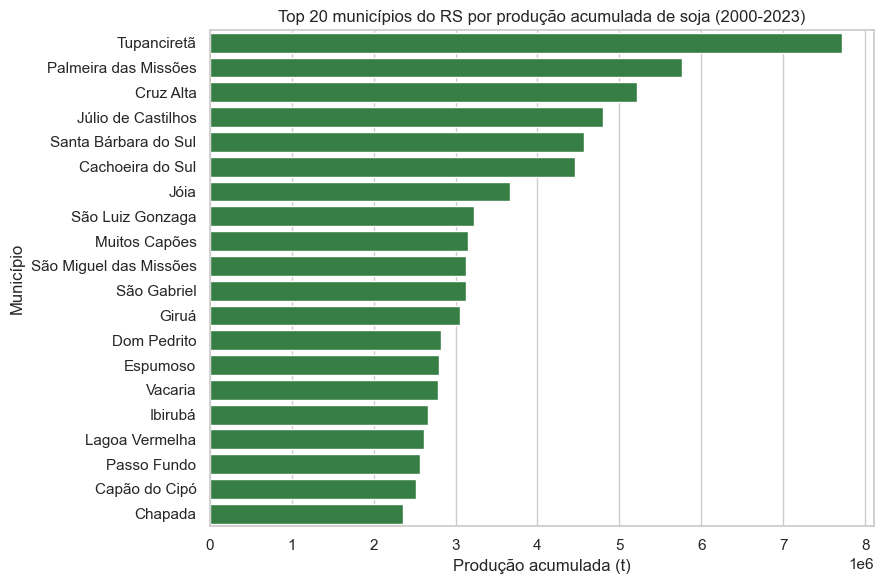

In [16]:
top = (base.groupby('municipio_nome')['producao_t'].sum(min_count=1)
            .sort_values(ascending=False).head(20).reset_index())
fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(data=top, y='municipio_nome', x='producao_t', color='#2b8a3e', ax=ax)
ax.set_title('Top 20 municípios do RS por produção acumulada de soja (2000-2023)')
ax.set_xlabel('Produção acumulada (t)')
ax.set_ylabel('Município')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '04_top20_produtores.png'), dpi=120)
plt.show()

### 4.7 Correlações entre variáveis quantitativas

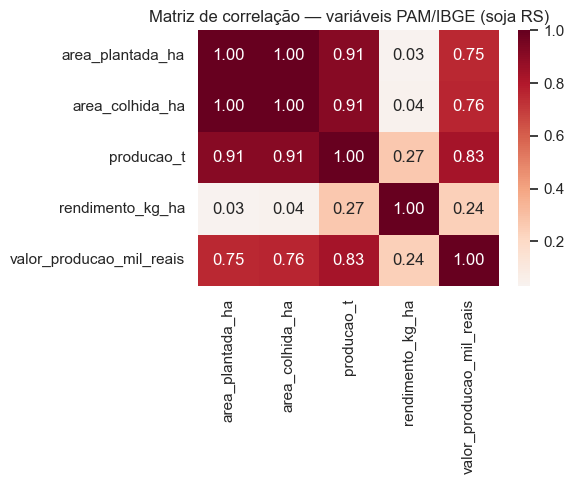

In [17]:
corr = base[['area_plantada_ha', 'area_colhida_ha', 'producao_t',
             'rendimento_kg_ha', 'valor_producao_mil_reais']].corr()
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, ax=ax)
ax.set_title('Matriz de correlação — variáveis PAM/IBGE (soja RS)')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '05_correlacoes.png'), dpi=120)
plt.show()

### 4.8 Análise de valores extremos (sem exclusão automática)

Conforme discutido na seção 4.3 do relatório, valores extremos podem representar safras muito favoráveis ou muito prejudicadas por eventos climáticos, e serão preservados. A análise aqui identifica quais observações se afastam mais do padrão para futura investigação qualitativa.

In [18]:
q1, q3 = base['rendimento_kg_ha'].quantile([0.25, 0.75])
iqr = q3 - q1
limite_inf = q1 - 1.5 * iqr
limite_sup = q3 + 1.5 * iqr
print(f'Limite inferior (IQR): {limite_inf:.1f} kg/ha  |  Limite superior (IQR): {limite_sup:.1f} kg/ha')

extremos_baixos = base[base['rendimento_kg_ha'] < limite_inf].sort_values('rendimento_kg_ha').head(15)
extremos_altos  = base[base['rendimento_kg_ha'] > limite_sup].sort_values('rendimento_kg_ha', ascending=False).head(15)
print('\nExtremos baixos (potenciais quebras de safra):')
display(extremos_baixos[['municipio_nome','ano','area_colhida_ha','producao_t','rendimento_kg_ha']])
print('\nExtremos altos:')
display(extremos_altos[['municipio_nome','ano','area_colhida_ha','producao_t','rendimento_kg_ha']])

Limite inferior (IQR): -42.5 kg/ha  |  Limite superior (IQR): 4825.5 kg/ha

Extremos baixos (potenciais quebras de safra):


,municipio_nome,ano,area_colhida_ha,producao_t,rendimento_kg_ha



Extremos altos:


,municipio_nome,ano,area_colhida_ha,producao_t,rendimento_kg_ha


### 4.9 Referência histórica por município (linha de base)

Para uso posterior como *baseline* do modelo, calculamos, para cada município-safra, a **média histórica** utilizando apenas safras anteriores — evitando vazamento de informação futura no atributo de contexto.

In [19]:
def media_expandida_shift(s):
    return s.shift(1).expanding().mean()

base_ord = base.sort_values(['codigo_municipio', 'ano']).copy()
base_ord['media_hist_mun'] = (base_ord.groupby('codigo_municipio')['rendimento_kg_ha']
                                       .transform(media_expandida_shift))
base_ord['rendimento_anterior'] = base_ord.groupby('codigo_municipio')['rendimento_kg_ha'].shift(1)
base_ord[['municipio_nome','ano','rendimento_kg_ha','rendimento_anterior','media_hist_mun']].head(15)

,municipio_nome,ano,rendimento_kg_ha,rendimento_anterior,media_hist_mun
0,Aceguá,2001,1260.0,NaN,NaN
1,Aceguá,2002,1260.0,1260.0,1260.000000
2,Aceguá,2003,1260.0,1260.0,1260.000000
3,Aceguá,2004,1260.0,1260.0,1260.000000
4,Aceguá,2005,240.0,1260.0,1260.000000
5,Aceguá,2006,1200.0,240.0,1056.000000
6,Aceguá,2007,1580.0,1200.0,1080.000000
7,Aceguá,2008,1740.0,1580.0,1151.428571
8,Aceguá,2009,1750.0,1740.0,1225.000000
9,Aceguá,2010,1750.0,1750.0,1283.333333


## 5. Integração do sinal ENOS — Oceanic Niño Index (NOAA/CPC)

**Fonte:** NOAA/CPC — [ONI](https://www.cpc.ncep.noaa.gov/data/indices/oni.ascii.txt). Convenção: `ANOM ≥ +0.5°C` classifica **El Niño**; `ANOM ≤ −0.5°C` classifica **La Niña**; caso contrário, **Neutro**. Cada linha da série é uma média móvel trimestral (DJF, JFM, ...).

In [20]:
oni = pd.read_csv(os.path.join(DATA_DIR, 'oni_nino34.csv'))
oni.head()

,SEAS,YR,TOTAL,ANOM,fase_enso
0,DJF,1999,25.12,-1.51,La Nina
1,JFM,1999,25.60,-1.25,La Nina
2,FMA,1999,26.31,-0.93,La Nina
3,MAM,1999,26.80,-0.80,La Nina
4,AMJ,1999,26.94,-0.79,La Nina


In [21]:
# Sinal médio ONI para a janela de desenvolvimento da soja no RS:
# Como o plantio ocorre entre outubro e dezembro e a colheita entre março e maio,
# usamos a média do ONI dos trimestres OND, NDJ, DJF, JFM, FMA como resumo pré-safra.
trimestres_safra = ['OND', 'NDJ', 'DJF', 'JFM', 'FMA']

# 'safra' relaciona-se ao ano-calendário da colheita (=YR do trimestre que fecha a safra)
oni_saf = oni[oni['SEAS'].isin(trimestres_safra)].copy()
# Mapeamento simples: OND, NDJ -> safra do ano seguinte (YR+1); DJF/JFM/FMA -> mesmo YR
oni_saf['safra'] = np.where(oni_saf['SEAS'].isin(['OND', 'NDJ']), oni_saf['YR'] + 1, oni_saf['YR'])

oni_agg = (oni_saf.groupby('safra')['ANOM']
                  .agg(['mean', 'min', 'max'])
                  .rename(columns={'mean': 'oni_medio_safra',
                                   'min':  'oni_min_safra',
                                   'max':  'oni_max_safra'})
                  .reset_index())

def fase(v):
    if v >= 0.5: return 'El Nino'
    if v <= -0.5: return 'La Nina'
    return 'Neutro'

oni_agg['fase_dominante_safra'] = oni_agg['oni_medio_safra'].apply(fase)
oni_agg.tail(10)

,safra,oni_medio_safra,oni_min_safra,oni_max_safra,fase_dominante_safra
18,2017,-0.118,-0.49,0.27,Neutro
19,2018,-0.660,-0.76,-0.55,La Nina
20,2019,0.978,0.87,1.05,El Nino
21,2020,0.682,0.57,0.75,El Nino
22,2021,-0.950,-1.11,-0.74,La Nina
23,2022,-0.790,-0.91,-0.68,La Nina
24,2023,-0.502,-0.82,-0.11,La Nina
25,2024,1.688,1.18,1.99,El Nino
26,2025,-0.296,-0.46,-0.08,Neutro
27,2026,-0.340,-0.61,0.11,Neutro


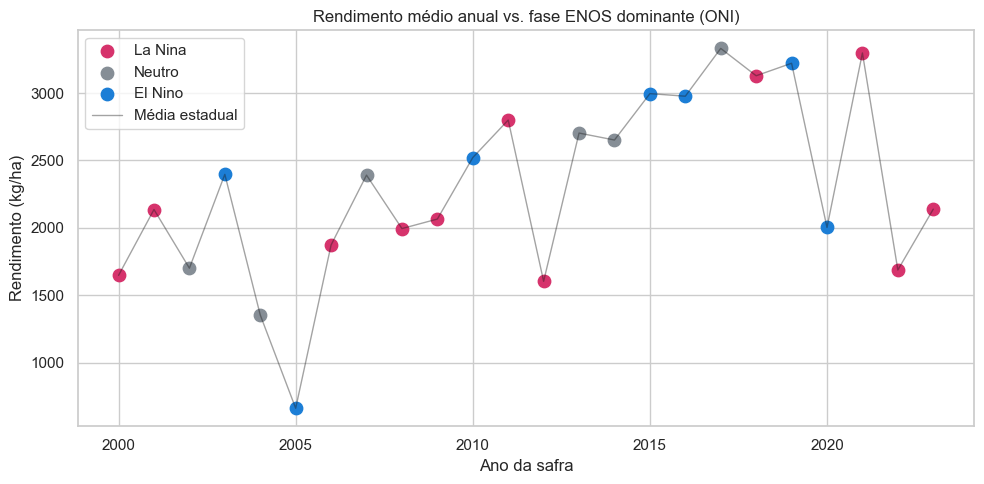

In [22]:
base_enos = base_ord.merge(oni_agg, left_on='ano', right_on='safra', how='left')

resumo_enso = (base_enos.dropna(subset=['rendimento_kg_ha', 'fase_dominante_safra'])
                        .groupby(['ano', 'fase_dominante_safra'])['rendimento_kg_ha']
                        .mean().reset_index())

fig, ax = plt.subplots(figsize=(10, 5))
for fase_lbl, cor in [('La Nina', '#d6336c'), ('Neutro', '#868e96'), ('El Nino', '#1c7ed6')]:
    sub = resumo_enso[resumo_enso['fase_dominante_safra'] == fase_lbl]
    ax.scatter(sub['ano'], sub['rendimento_kg_ha'], color=cor, label=fase_lbl, s=80)
ax.plot(evol['ano'], evol['media'], color='k', alpha=0.4, linewidth=1, label='Média estadual')
ax.set_title('Rendimento médio anual vs. fase ENOS dominante (ONI)')
ax.set_xlabel('Ano da safra')
ax.set_ylabel('Rendimento (kg/ha)')
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '06_enso_vs_rendimento.png'), dpi=120)
plt.show()

In [23]:
print('Rendimento médio por fase ENOS (todas as safras do RS):')
print(base_enos.groupby('fase_dominante_safra')['rendimento_kg_ha']
                .agg(['mean', 'median', 'count']).round(1))

Rendimento médio por fase ENOS (todas as safras do RS):
                        mean  median  count
fase_dominante_safra                       
El Nino               2411.7  2638.0   2853
La Nina               2229.6  2210.0   4417
Neutro                2374.3  2400.0   2405


## 6. Salvamento da base preparada e próximos passos

A base a seguir consolida os dados da PAM/IBGE, as *baselines* históricas e o sinal ENOS. Ela servirá de ponto de partida para a **etapa N2**, quando serão integradas as variáveis agrometeorológicas (NASA POWER, INMET) e treinados os modelos Ridge, Random Forest e Gradient Boosting.

In [24]:
saida = os.path.join(DATA_DIR, 'base_soja_rs_N1.csv')
base_enos.to_csv(saida, index=False)
print('Base final N1 salva em:', saida)
print('Shape:', base_enos.shape)
base_enos.head()

Base final N1 salva em: /Users/gustavoaugustogarcia/Downloads/pedro fedido 2026/dados/base_soja_rs_N1.csv
Shape: (9692, 15)


,codigo_municipio,municipio_nome,ano,area_plantada_ha,area_colhida_ha,producao_t,rendimento_kg_ha,valor_producao_mil_reais,media_hist_mun,rendimento_anterior,safra,oni_medio_safra,oni_min_safra,oni_max_safra,fase_dominante_safra
0,4300034,Aceguá,2001,100.0,100.0,126.0,1260.0,47.0,NaN,NaN,2001,-0.654,-0.78,-0.43,La Nina
1,4300034,Aceguá,2002,100.0,100.0,126.0,1260.0,55.0,1260.0,1260.0,2002,-0.124,-0.33,0.11,Neutro
2,4300034,Aceguá,2003,750.0,750.0,945.0,1260.0,624.0,1260.0,1260.0,2003,0.828,0.38,1.19,El Nino
3,4300034,Aceguá,2004,750.0,750.0,945.0,1260.0,650.0,1260.0,1260.0,2004,0.276,0.19,0.34,Neutro
4,4300034,Aceguá,2005,2000.0,2000.0,480.0,240.0,204.0,1260.0,1260.0,2005,0.584,0.40,0.71,El Nino


### Roteiro de captura NASA POWER (a ser executado na N2)

O bloco abaixo (comentado) documenta a chamada à API POWER para uma coordenada representativa do RS. Na N2 será executado para os centróides dos municípios e as séries diárias serão agregadas em atributos por janela da safra (chuva acumulada, dias secos, temperaturas extremas, radiação, umidade, graus-dia).

```python
# lat, lon = -29.68, -53.81  # exemplo: Santa Maria/RS
# start, end = '20200101', '20231231'
# params = 'PRECTOTCORR,T2M,T2M_MAX,T2M_MIN,RH2M,ALLSKY_SFC_SW_DWN'
# url = (f'https://power.larc.nasa.gov/api/temporal/daily/point?'
#        f'parameters={params}&community=AG&latitude={lat}&longitude={lon}'
#        f'&start={start}&end={end}&format=JSON')
# r = requests.get(url, timeout=120)
```